<a href="https://colab.research.google.com/github/VilasiniRamamoorthy/PlanetaryDenseAsteroidAnalytics/blob/main/Project2_Planetary_Defense_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Planetary Defense Analytics: Classifying and Predicting Asteroid Properties (V2)**

In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv('/content/pha_dataset.csv', low_memory=False)


In [ ]:
df.shape

(958524, 45)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958524 entries, 0 to 958523
Data columns (total 45 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              958524 non-null  object 
 1   spkid           958524 non-null  int64  
 2   full_name       958524 non-null  object 
 3   pdes            958524 non-null  object 
 4   name            22064 non-null   object 
 5   prefix          18 non-null      object 
 6   neo             958520 non-null  object 
 7   pha             938603 non-null  object 
 8   H               952261 non-null  float64
 9   diameter        136209 non-null  float64
 10  albedo          135103 non-null  float64
 11  diameter_sigma  136081 non-null  float64
 12  orbit_id        958524 non-null  object 
 13  epoch           958524 non-null  float64
 14  epoch_mjd       958524 non-null  int64  
 15  epoch_cal       958524 non-null  float64
 16  equinox         958524 non-null  object 
 17  e         

In [ ]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [ ]:
df.describe()

,spkid,H,diameter,albedo,diameter_sigma,epoch,epoch_mjd,epoch_cal,e,a,...,sigma_q,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,rms
count,9.585240e+05,952261.000000,136209.000000,135103.000000,136081.000000,9.585240e+05,958524.000000,9.585240e+05,958524.000000,958524.000000,...,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.386020e+05,9.385980e+05,9.386020e+05,9.386020e+05,9.385980e+05,958522.000000
mean,3.810114e+06,16.906411,5.506429,0.130627,0.479184,2.458869e+06,58868.781950,2.019693e+07,0.156116,2.902143,...,1.982929e+01,1.168449e+00,5.310234e+00,1.370062e+06,1.369977e+06,2.131453e+01,5.060221e-02,4.312780e+08,8.525815e+04,0.561153
std,6.831541e+06,1.790405,9.425164,0.110323,0.782895,7.016716e+02,701.671573,1.930354e+04,0.092643,39.719503,...,2.903785e+03,1.282231e+02,1.333381e+03,9.158996e+08,9.158991e+08,7.197034e+03,9.814953e+00,2.953046e+11,2.767681e+07,2.745700
min,2.000001e+06,-1.100000,0.002500,0.001000,0.000500,2.425052e+06,25051.000000,1.927062e+07,0.000000,-14702.447872,...,1.956900e-11,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,0.000000
25%,2.239632e+06,16.100000,2.780000,0.053000,0.180000,2.459000e+06,59000.000000,2.020053e+07,0.092193,2.387835,...,1.462000e-07,6.095900e-06,3.619400e-05,5.755000e-05,2.573700e-05,2.340900e-08,2.768800e-09,1.110900e-04,1.794500e-05,0.518040
50%,2.479262e+06,16.900000,3.972000,0.079000,0.332000,2.459000e+06,59000.000000,2.020053e+07,0.145002,2.646969,...,2.271900e-07,8.688800e-06,6.642550e-05,1.047100e-04,4.900100e-05,4.359000e-08,4.638000e-09,2.230800e-04,3.501700e-05,0.566280
75%,3.752518e+06,17.714000,5.765000,0.190000,0.620000,2.459000e+06,59000.000000,2.020053e+07,0.200650,3.001932,...,6.583200e-07,1.591500e-05,1.609775e-04,3.114400e-04,1.718900e-04,1.196600e-07,1.124000e-08,8.139600e-04,9.775475e-05,0.613927
max,5.401723e+07,33.200000,939.400000,1.000000,140.000000,2.459000e+06,59000.000000,2.020053e+07,1.855356,33488.895955,...,1.015000e+06,5.533000e+04,1.199100e+06,8.845100e+11,8.845100e+11,5.509700e+06,7.698800e+03,2.853100e+14,1.910700e+10,2686.600000


In [ ]:
# Missing values
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

display(
    missing.sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
prefix,958506,99.998122
name,936460,97.698128
albedo,823421,85.905100
diameter_sigma,822443,85.803068
diameter,822315,85.789714
sigma_per,19926,2.078821
sigma_ad,19926,2.078821
sigma_om,19922,2.078404
sigma_ma,19922,2.078404
sigma_q,19922,2.078404


In [ ]:
# Identifier columns
id_columns = [
    "id",
    "spkid",
    "pdes",
    "full_name",
    "name",
    "orbit_id"
]

# Find sigma columns
sigma_columns = [
    col for col in df.columns
    if col.lower().startswith("sigma_")
]

# Combine columns that exist
drop_columns = [
    col for col in id_columns + sigma_columns
    if col in df.columns
]

df.drop(
    columns=drop_columns,
    inplace=True
)

print("Remaining columns:", df.columns.tolist())

Remaining columns: ['prefix', 'neo', 'pha', 'H', 'diameter', 'albedo', 'diameter_sigma', 'epoch', 'epoch_mjd', 'epoch_cal', 'equinox', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld', 'class', 'rms']


In [ ]:
# Zero variance columns
zero_variance = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

# 100% unique columns
fully_unique = [
    col for col in df.columns
    if df[col].nunique(dropna=True) == len(df)
]

columns_to_remove = list(
    set(zero_variance + fully_unique)
)

df.drop(
    columns=columns_to_remove,
    inplace=True
)

print("Removed columns:", columns_to_remove)

Removed columns: ['equinox']


In [ ]:
# Count duplicate records
print("Duplicate records:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Duplicate records: 0
Shape after removing duplicates: (958524, 27)


In [ ]:
# Check invalid eccentricity
print("Invalid eccentricity:", (df["e"] < 0).sum())

# Check invalid semi-major axis
print("Invalid semi-major axis:", (df["a"] <= 0).sum())

# Check invalid diameter
print("Invalid diameter:", (df["diameter"] < 0).sum())

# Check invalid albedo
print(
    "Invalid albedo:",
    ((df["albedo"] < 0) | (df["albedo"] > 1)).sum()
)

Invalid eccentricity: 0
Invalid semi-major axis: 4
Invalid diameter: 0
Invalid albedo: 0


In [ ]:
df = df[
    (df["e"].isna() | (df["e"] >= 0)) &
    (df["a"].isna() | (df["a"] > 0)) &
    (df["diameter"].isna() | (df["diameter"] >= 0)) &
    (df["albedo"].isna() |
     ((df["albedo"] >= 0) & (df["albedo"] <= 1)))
].copy()

In [ ]:
import numpy as np
# Check unique values in numerical columns

numeric_columns = df.select_dtypes(
    include=np.number
).columns

for col in numeric_columns:

    print(f"\nColumn: {col}")

    print(df[col].value_counts().head(10))


Column: H
H
16.8    28602
16.9    28515
16.7    28273
17.0    28029
16.6    27969
16.5    27694
17.1    27243
17.2    26575
16.4    26285
17.3    25463
Name: count, dtype: int64

Column: diameter
diameter
4.017    45
3.296    45
3.122    44
3.537    44
3.008    44
3.377    44
3.111    43
2.613    43
3.140    43
3.355    43
Name: count, dtype: int64

Column: albedo
albedo
0.057    1652
0.055    1646
0.053    1637
0.052    1623
0.049    1621
0.051    1618
0.048    1595
0.056    1593
0.054    1587
0.050    1584
Name: count, dtype: int64

Column: diameter_sigma
diameter_sigma
0.169    316
0.167    313
0.162    312
0.147    312
0.172    303
0.189    300
0.197    298
0.143    297
0.157    297
0.152    297
Name: count, dtype: int64

Column: epoch
epoch
2459000.5    909386
2458600.5      7725
2457689.5      1506
2456720.5      1161
2456400.5       621
2456399.5       524
2456298.5       510
2457042.5       394
2456719.5       367
2456867.5       268
Name: count, dtype: int64

Column: epoch_mj

In [ ]:
display(
    df[numeric_columns].describe().T[
        ["min", "max", "mean", "std"]
    ]
)

,min,max,mean,std
H,-1.100000e+00,3.320000e+01,1.690642e+01,1.790369e+00
diameter,2.500000e-03,9.394000e+02,5.506429e+00,9.425164e+00
albedo,1.000000e-03,1.000000e+00,1.306272e-01,1.103228e-01
diameter_sigma,5.000000e-04,1.400000e+02,4.791844e-01,7.828952e-01
epoch,2.425052e+06,2.459000e+06,2.458869e+06,7.016678e+02
epoch_mjd,2.505100e+04,5.900000e+04,5.886879e+04,7.016678e+02
epoch_cal,1.927062e+07,2.020053e+07,2.019693e+07,1.930344e+04
e,0.000000e+00,9.998508e-01,1.561117e-01,9.261238e-02
a,5.554178e-01,3.348890e+04,2.925348e+00,3.595804e+01
q,7.051073e-02,8.039882e+01,2.394876e+00,2.139234e+00


In [ ]:
infinity_count = pd.DataFrame({
    "Positive_Infinity": np.isposinf(
        df[numeric_columns]
    ).sum(),

    "Negative_Infinity": np.isneginf(
        df[numeric_columns]
    ).sum()
})

display(infinity_count)

,Positive_Infinity,Negative_Infinity
H,0,0
diameter,0,0
albedo,0,0
diameter_sigma,0,0
epoch,0,0
epoch_mjd,0,0
epoch_cal,0,0
e,0,0
a,0,0
q,0,0


In [ ]:
df[numeric_columns] = df[numeric_columns].replace(
    [np.inf, -np.inf],
    np.nan
)

In [ ]:
df

,prefix,neo,pha,H,diameter,albedo,diameter_sigma,epoch,epoch_mjd,epoch_cal,...,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,class,rms
0,NaN,N,N,3.400,939.400,0.0900,0.200,2458600.5,58600,20190427.0,...,2.979647,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.594780,620.640533,MBA,0.43301
1,NaN,N,N,4.200,545.000,0.1010,18.000,2459000.5,59000,20200531.0,...,3.411748,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.234290,480.348639,MBA,0.35936
2,NaN,N,N,5.330,246.596,0.2140,10.594,2459000.5,59000,20200531.0,...,3.353865,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.034290,402.514639,MBA,0.33848
3,NaN,N,N,3.000,525.400,0.4228,0.200,2458600.5,58600,20190427.0,...,2.570926,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.139480,443.451432,MBA,0.39980
4,NaN,N,N,6.900,106.699,0.2740,3.140,2459000.5,59000,20200531.0,...,3.065455,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.095750,426.433027,MBA,0.52191
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958519,NaN,N,N,17.135,NaN,NaN,NaN,2437203.5,37203,19600926.0,...,2.704916,0.286125,2.437266e+06,1.960113e+07,1258.191614,3.444741,0.861979,335.456367,MBA,0.23839
958520,NaN,N,N,18.500,NaN,NaN,NaN,2459000.5,59000,20200531.0,...,2.995502,0.276248,2.459362e+06,2.021053e+07,1303.177916,3.567907,0.671242,261.227249,MBA,0.53633
958521,NaN,Y,Y,20.400,NaN,NaN,NaN,2459000.5,59000,20200531.0,...,4.683363,0.208444,2.459574e+06,2.021123e+07,1727.085364,4.728502,0.035589,13.850093,APO,0.51556
958522,NaN,N,N,18.071,NaN,NaN,NaN,2441956.5,41956,19731001.0,...,2.852636,0.269600,2.441974e+06,1.973102e+07,1335.311579,3.655884,0.893896,347.877506,MBA,0.25641


In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
prefix,958505
albedo,823417
diameter_sigma,822439
diameter,822311
pha,19921
moid,19921
H,6263
moid_ld,127
rms,2
ma,1


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
H,952257.0,1.690642e+01,1.790369e+00,-1.100000e+00,1.610000e+01,1.690000e+01,1.771400e+01,3.320000e+01
diameter,136209.0,5.506429e+00,9.425164e+00,2.500000e-03,2.780000e+00,3.972000e+00,5.765000e+00,9.394000e+02
albedo,135103.0,1.306272e-01,1.103228e-01,1.000000e-03,5.300000e-02,7.900000e-02,1.900000e-01,1.000000e+00
diameter_sigma,136081.0,4.791844e-01,7.828952e-01,5.000000e-04,1.800000e-01,3.320000e-01,6.200000e-01,1.400000e+02
epoch,958520.0,2.458869e+06,7.016678e+02,2.425052e+06,2.459000e+06,2.459000e+06,2.459000e+06,2.459000e+06
epoch_mjd,958520.0,5.886879e+04,7.016678e+02,2.505100e+04,5.900000e+04,5.900000e+04,5.900000e+04,5.900000e+04
epoch_cal,958520.0,2.019693e+07,1.930344e+04,1.927062e+07,2.020053e+07,2.020053e+07,2.020053e+07,2.020053e+07
e,958520.0,1.561117e-01,9.261238e-02,0.000000e+00,9.219240e-02,1.450011e-01,2.006494e-01,9.998508e-01
a,958520.0,2.925348e+00,3.595804e+01,5.554178e-01,2.387837e+00,2.646970e+00,3.001933e+00,3.348890e+04
q,958520.0,2.394876e+00,2.139234e+00,7.051073e-02,1.971401e+00,2.225815e+00,2.578311e+00,8.039882e+01


In [ ]:
numeric_columns = df.select_dtypes(
    include=np.number
).columns

skewness = df[numeric_columns].skew()

print(
    skewness.sort_values(
        ascending=False
    )
)

rms               976.734005
per_y             953.004604
per               953.004604
ad                864.424060
a                 859.266283
diameter_sigma     69.824037
diameter           25.852418
q                  15.837971
moid               15.755948
moid_ld            15.746155
n                   5.623794
i                   2.171836
e                   1.891389
albedo              1.683567
H                   0.604838
om                  0.198258
ma                  0.040668
w                  -0.020327
tp_cal             -4.633676
tp                 -4.675626
epoch_mjd          -6.858181
epoch              -6.858181
epoch_cal          -6.864261
dtype: float64


In [ ]:
Q1 = df["H"].quantile(0.25)
Q3 = df["H"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["H"] < lower_limit) |
    (df["H"] > upper_limit)
]

print("Outliers in H:", len(outliers))

Outliers in H: 44538


In [ ]:
# Calculate IQR limits for H
Q1 = df["H"].quantile(0.25)
Q3 = df["H"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify outliers
h_outliers = df[
    (df["H"] < lower_limit) |
    (df["H"] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of outliers:", len(h_outliers))

display(h_outliers["H"].describe())

Lower limit: 13.679000000000006
Upper limit: 20.134999999999994
Number of outliers: 44538


,H
count,44538.000000
mean,17.544055
std,6.219502
min,-1.100000
25%,12.888000
50%,13.600000
75%,23.200000
max,33.200000


In [ ]:
# Keep only rows with observed PHA target
case1_df = df.dropna(subset=["pha"]).copy()

# Standardize target labels
case1_df["pha"] = (
    case1_df["pha"]
    .astype(str)
    .str.strip()
    .str.upper()
)

# Keep only valid binary labels
case1_df = case1_df[
    case1_df["pha"].isin(["Y", "N"])
].copy()

# Select classification features
case1_features = [
    "H", "e", "a", "i", "om", "w", "ma"
]

X1 = case1_df[case1_features]
y1 = case1_df["pha"]

print("Case 1 shape:", X1.shape)
print(y1.value_counts())

Case 1 shape: (938599, 7)
pha
N    936533
Y      2066
Name: count, dtype: int64


In [ ]:
# Keep only rows with observed diameter
case2_df = df.dropna(subset=["diameter"]).copy()

# Select regression features
case2_features = [
    "H", "albedo", "e", "a", "i", "om", "w", "ma"
]

X2 = case2_df[case2_features]
y2 = case2_df["diameter"]

print("Case 2 shape:", X2.shape)
print("Target missing values:", y2.isnull().sum())

Case 2 shape: (136209, 8)
Target missing values: 0


In [ ]:
from sklearn.model_selection import train_test_split

# Case 1: Classification
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1,
    y1,
    test_size=0.20,
    random_state=42,
    stratify=y1
)

# Case 2: Regression
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2,
    y2,
    test_size=0.20,
    random_state=42
)

print("Case 1 training:", X1_train.shape)
print("Case 1 testing:", X1_test.shape)

print("Case 2 training:", X2_train.shape)
print("Case 2 testing:", X2_test.shape)

Case 1 training: (750879, 7)
Case 1 testing: (187720, 7)
Case 2 training: (108967, 8)
Case 2 testing: (27242, 8)


In [ ]:
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer

# Numerical features
case1_numeric = ["H", "e", "a", "i"]

case2_numeric = [
    "H", "albedo", "e", "a", "i"
]

# Cyclic features
angle_features = ["om", "w", "ma"]


# Convert angles into sine and cosine
def angle_to_sin_cos(X):

    X = np.asarray(X, dtype=float)

    radians = np.deg2rad(X)

    return np.column_stack([
        np.sin(radians),
        np.cos(radians)
    ])


# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# Angular preprocessing
angle_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("cyclic", FunctionTransformer(
        angle_to_sin_cos,
        validate=False
    ))
])


# Case 1 preprocessing
preprocessor1 = ColumnTransformer([
    ("numeric", numeric_pipeline, case1_numeric),
    ("angles", angle_pipeline, angle_features)
])


# Case 2 preprocessing
preprocessor2 = ColumnTransformer([
    ("numeric", numeric_pipeline, case2_numeric),
    ("angles", angle_pipeline, angle_features)
])

In [ ]:
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)

# Case 1: Classification pipeline
case1_pipeline = Pipeline([
    ("preprocessing", preprocessor1),
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])


# Case 2: Regression pipeline
case2_pipeline = Pipeline([
    ("preprocessing", preprocessor2),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])


# Train models
case1_pipeline.fit(X1_train, y1_train)

case2_pipeline.fit(X2_train, y2_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['H', 'albedo', 'e', 'a',
                                                   'i']),
                                                 ('angles',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('cyclic',
                                                                   FunctionTransformer(func=<function angle_to_sin_cos at 0x7dc887c028e0>))]),
                                                  ['om', 'w', 'ma'])])),
                ('model',
                 RandomForestRegressor(n_estimators=200, random_state=42))])

In [41]:
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)

# Case 1: Classification pipeline
case1_pipeline = Pipeline([
    ("preprocessing", preprocessor1),
    ("model", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])


# Case 2: Regression pipeline
case2_pipeline = Pipeline([
    ("preprocessing", preprocessor2),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])


# Train models
case1_pipeline.fit(X1_train, y1_train)

case2_pipeline.fit(X2_train, y2_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['H', 'albedo', 'e', 'a',
                                                   'i']),
                                                 ('angles',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('cyclic',
                                                                   FunctionTransformer(func=<function angle_to_sin_cos at 0x7dc887c028e0>))]),
                                                  ['om', 'w', 'ma'])])),
                ('model',
                 RandomForestRegressor(n_estimators=200, random_state=42))])

In [42]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y1_pred = case1_pipeline.predict(X1_test)

print("Accuracy:",
      accuracy_score(y1_test, y1_pred))

print("\nClassification Report:")
print(classification_report(y1_test, y1_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y1_test, y1_pred))

Accuracy: 0.9981834647347113

Classification Report:
              precision    recall  f1-score   support

           N       1.00      1.00      1.00    187307
           Y       0.78      0.24      0.37       413

    accuracy                           1.00    187720
   macro avg       0.89      0.62      0.68    187720
weighted avg       1.00      1.00      1.00    187720


Confusion Matrix:
[[187279     28]
 [   313    100]]


In [43]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

y2_pred = case2_pipeline.predict(X2_test)

mae = mean_absolute_error(y2_test, y2_pred)

rmse = np.sqrt(
    mean_squared_error(y2_test, y2_pred)
)

r2 = r2_score(y2_test, y2_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.4349654810586595
RMSE: 2.3623680445836426
R2 Score: 0.9446790106999505


In [44]:
import joblib
import os

os.makedirs("models", exist_ok=True)

# Save Case 1
joblib.dump(
    case1_pipeline,
    "models/case1_pha_pipeline.pkl"
)

# Save Case 2
joblib.dump(
    case2_pipeline,
    "models/case2_diameter_pipeline.pkl"
)

print("Both pipelines saved successfully!")

Both pipelines saved successfully!


In [46]:
print("Training data shape:", X1_train.shape)
print("Testing data shape:", X1_test.shape)

print("Training target shape:", y1_train.shape)
print("Testing target shape:", y1_test.shape)

Training data shape: (750879, 7)
Testing data shape: (187720, 7)
Training target shape: (750879,)
Testing target shape: (187720,)


In [47]:
print(case1_pipeline)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['H', 'e', 'a', 'i']),
                                                 ('angles',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('cyclic',
                                                                   FunctionTransformer(func=<function angle_to_sin_cos at 0x7dc887c028e0>))]),
                           

In [48]:
print(case1_pipeline.named_steps)

{'preprocessing': ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['H', 'e', 'a', 'i']),
                                ('angles',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('cyclic',
                                                  FunctionTransformer(func=<function angle_to_sin_cos at 0x7dc887c028e0>))]),
                                 ['om', 'w', 'ma'])]), 'model': RandomForestClassifier(class_weight='balanced', n_estimators=200,
                       random_state=42)}


In [50]:
rf = case1_pipeline.named_steps["rf"]

print("Number of trees:", rf.n_estimators)
print("Maximum depth:", rf.max_depth)

KeyError: 'rf'

In [51]:
from sklearn.ensemble import RandomForestClassifier

for name, step in case1_pipeline.named_steps.items():

    if isinstance(step, RandomForestClassifier):

        print("Model step name:", name)
        print("Number of trees:", step.n_estimators)
        print("Maximum depth:", step.max_depth)

Model step name: model
Number of trees: 200
Maximum depth: None


In [ ]:
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())

Duplicates before: 0
Duplicates after: 0


In [ ]:
print("Duplicate asteroid IDs:", df["spkid"].duplicated().sum())

Duplicate asteroid IDs: 0


In [ ]:
df = df.dropna(axis=1, how="all")

In [ ]:
columns_to_drop = df.columns[
    df.columns.str.startswith("sigma")]

df = df.drop(columns=columns_to_drop)

In [ ]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,2.979647,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.59478,620.640533,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.411748,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.23429,480.348639,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.353865,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.03429,402.514639,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.570926,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.13948,443.451432,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,3.065455,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.09575,426.433027,MBA,0.52191


In [ ]:
import numpy as np

# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Find columns where all values are zero
zero_columns = numeric_df.columns[
    (numeric_df == 0).all()
]

print("Columns containing only zeros:", list(zero_columns))

# Drop those columns
df = df.drop(columns=zero_columns)

print("Updated dataset shape:", df.shape)

Columns containing only zeros: []
Updated dataset shape: (958524, 34)


In [ ]:
import pandas as pd
import numpy as np

from sklearn.feature_selection import VarianceThreshold

# Select only numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Identify zero-variance columns
selector = VarianceThreshold(threshold=0)

selector.fit(numeric_df)

# Get constant columns
constant_columns = numeric_df.columns[
    ~selector.get_support()
]

print("Zero variance columns:", list(constant_columns))

# Remove constant columns
df = df.drop(columns=constant_columns)

print("Updated dataset shape:", df.shape)

Zero variance columns: []
Updated dataset shape: (958524, 34)


In [ ]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,ad,n,tp,tp_cal,per,per_y,moid,moid_ld,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,2.979647,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.59478,620.640533,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.411748,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.23429,480.348639,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.353865,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.03429,402.514639,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.570926,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.13948,443.451432,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,3.065455,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.09575,426.433027,MBA,0.52191


In [ ]:
#Handling missing values numeric and categorical columns

valid_rows = y.notna()

X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

# Fill missing numerical feature values with median

numeric_columns = X.select_dtypes(include=["number"]).columns

X[numeric_columns] = X[numeric_columns].fillna(
    X[numeric_columns].median()
)

print("Remaining missing values:", X.isnull().sum().sum())

categorical_columns = X.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_columns:
    X[col] = X[col].fillna(
        X[col].mode()[0] if not X[col].mode().empty else "Unknown"
    )

print("Missing values after cleaning:", X.isnull().sum().sum())

Remaining missing values: 2793731
Missing values after cleaning: 0


In [ ]:
df.shape

(958524, 35)

In [ ]:
df.head()

,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,n,tp,tp_cal,per,per_y,moid,moid_ld,class,rms,pha_label
0,a0000001,2000001.0,1 Ceres,1,Ceres,NaN,N,N,13.679,939.400,...,0.213885,2.458239e+06,2.018043e+07,1683.145703,4.608202,1.59478,620.640533,MBA,0.433010,NaN
1,a0000002,2000002.0,2 Pallas,2,Pallas,NaN,N,N,13.679,545.000,...,0.213345,2.458321e+06,2.018072e+07,1687.410992,4.619880,1.23429,480.348639,MBA,0.374209,NaN
2,a0000003,2000003.0,3 Juno,3,Juno,NaN,N,N,13.679,246.596,...,0.226129,2.458446e+06,2.018112e+07,1592.013769,4.358696,1.03429,402.514639,MBA,0.374209,NaN
3,a0000004,2000004.0,4 Vesta,4,Vesta,NaN,N,N,13.679,525.400,...,0.271609,2.458248e+06,2.018051e+07,1325.432763,3.628837,1.13948,443.451432,MBA,0.399800,NaN
4,a0000005,2000005.0,5 Astraea,5,Astraea,NaN,N,N,13.679,106.699,...,0.238661,2.458926e+06,2.020032e+07,1508.414421,4.129814,1.09575,426.433027,MBA,0.521910,NaN


In [ ]:
print(df.columns.tolist())

['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix', 'neo', 'pha', 'H', 'diameter', 'albedo', 'diameter_sigma', 'orbit_id', 'epoch', 'epoch_mjd', 'epoch_cal', 'equinox', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld', 'class', 'rms', 'pha_label']


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

H Outliers: 0
diameter Outliers: 9613
albedo Outliers: 3555
diameter_sigma Outliers: 6878
epoch Outliers: 0
epoch_mjd Outliers: 0
epoch_cal Outliers: 0
e Outliers: 0
a Outliers: 0
q Outliers: 0
i Outliers: 0
om Outliers: 0
w Outliers: 0
ma Outliers: 0
ad Outliers: 0
n Outliers: 0
tp Outliers: 0
tp_cal Outliers: 0
per Outliers: 0
per_y Outliers: 0
moid Outliers: 0
moid_ld Outliers: 0
rms Outliers: 0


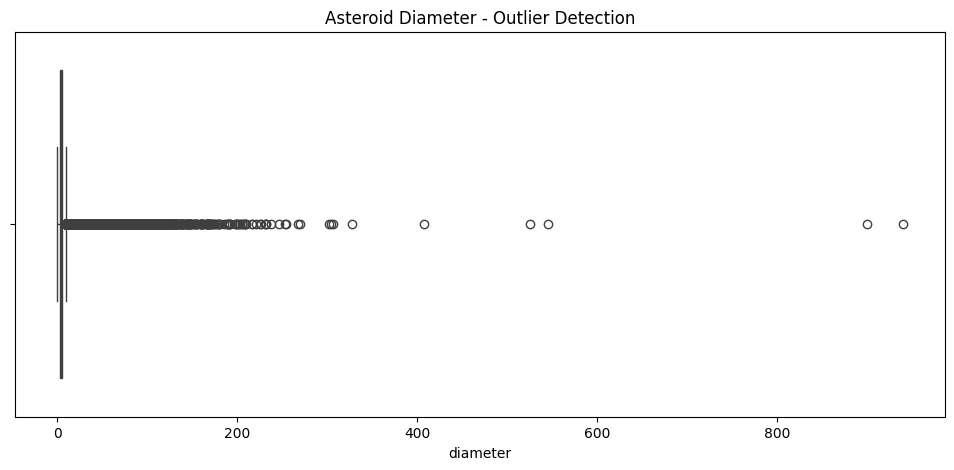

In [ ]:

for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(col, "Outliers:", len(outliers))

plt.figure(figsize=(12, 5))

sns.boxplot(x=df["diameter"])

plt.title("Asteroid Diameter - Outlier Detection")

plt.show()

In [ ]:
for col in numeric_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower,
        upper=upper
    )


#calc for skewness
skew_values = df[numeric_columns].skew()

print(skew_values.sort_values(ascending=False))

#positive highly right skewed
skewed_columns = [
    col for col in numeric_columns
    if df[col].min() >= 0 and df[col].skew() > 1
]

for col in skewed_columns:

    df[col] = np.log1p(df[col])

print("Transformed columns:", skewed_columns)



albedo            1.156015
diameter_sigma    1.055152
diameter          0.958134
i                 0.937240
e                 0.592488
n                 0.489694
per               0.283125
per_y             0.283048
om                0.198256
a                 0.168974
ad                0.167453
moid              0.041289
ma                0.040664
q                 0.023905
epoch_mjd         0.000000
epoch             0.000000
epoch_cal         0.000000
w                -0.020330
H                -0.088597
moid_ld          -0.216831
rms              -0.257071
tp_cal           -0.303355
tp               -0.499144
dtype: float64
Transformed columns: ['albedo', 'diameter_sigma']


In [ ]:
print(df.columns.tolist())

['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix', 'neo', 'pha', 'H', 'diameter', 'albedo', 'diameter_sigma', 'orbit_id', 'epoch', 'epoch_mjd', 'epoch_cal', 'equinox', 'e', 'a', 'q', 'i', 'om', 'w', 'ma', 'ad', 'n', 'tp', 'tp_cal', 'per', 'per_y', 'moid', 'moid_ld', 'class', 'rms', 'pha_label']


In [ ]:
df["pha_label"] = df["pha"].map({
    1: "Potentially Hazardous",
    0: "Non-Potentially Hazardous"
})

print(df["pha_label"].value_counts())

Series([], Name: count, dtype: int64)


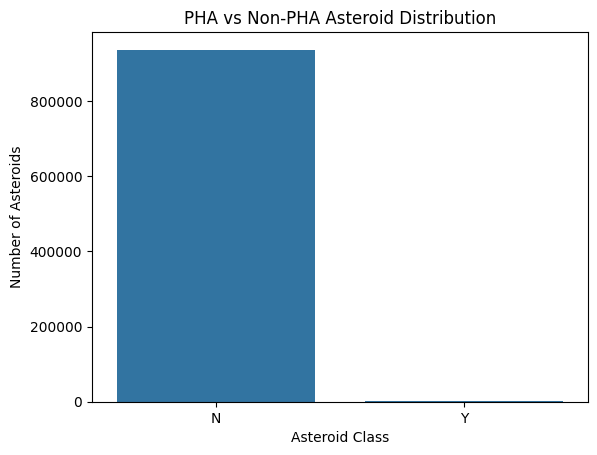

In [ ]:
#Visulization
sns.countplot(data=df, x="pha")

plt.title("PHA vs Non-PHA Asteroid Distribution")
plt.xlabel("Asteroid Class")
plt.ylabel("Number of Asteroids")

plt.show()

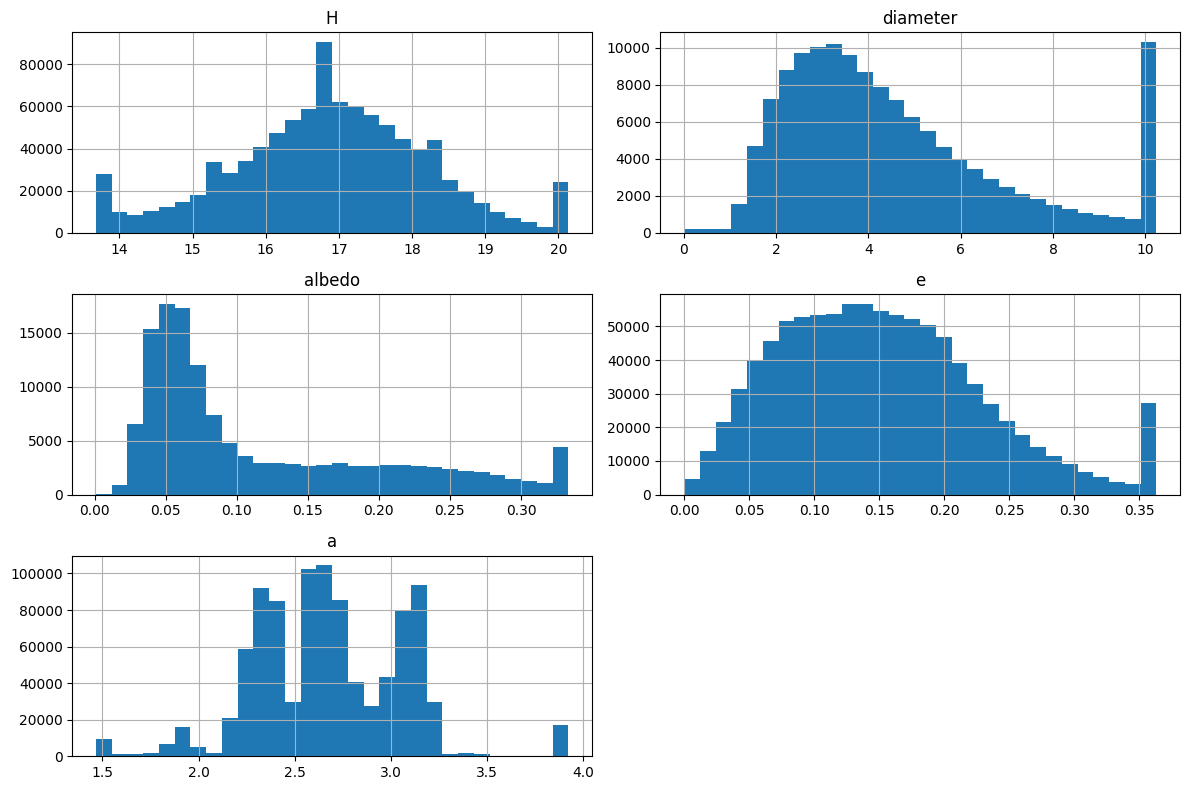

In [ ]:
#numeric distribution
df[["H", "diameter", "albedo", "e", "a"]].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

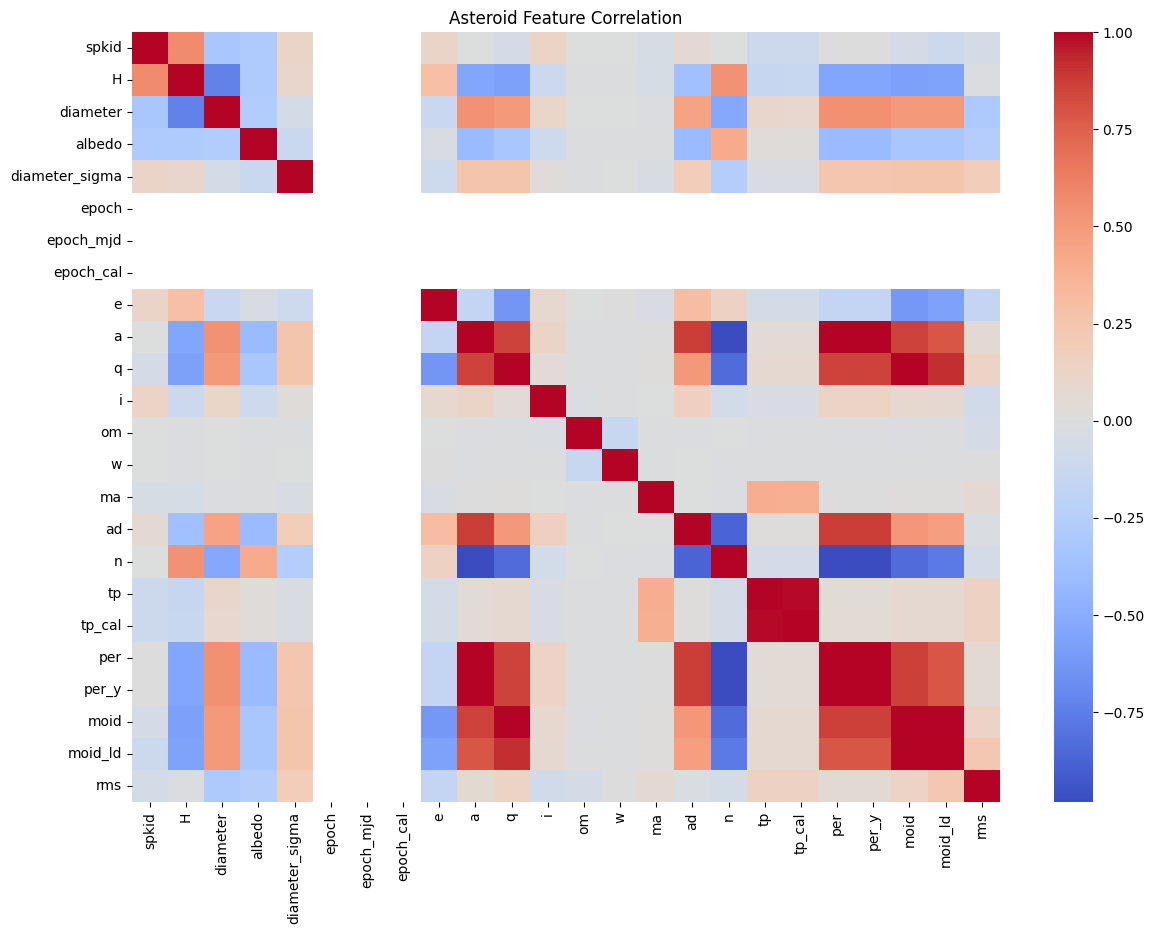

In [ ]:
#correlation heapmap
plt.figure(figsize=(14, 10))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    annot=False
)

plt.title("Asteroid Feature Correlation")

plt.show()

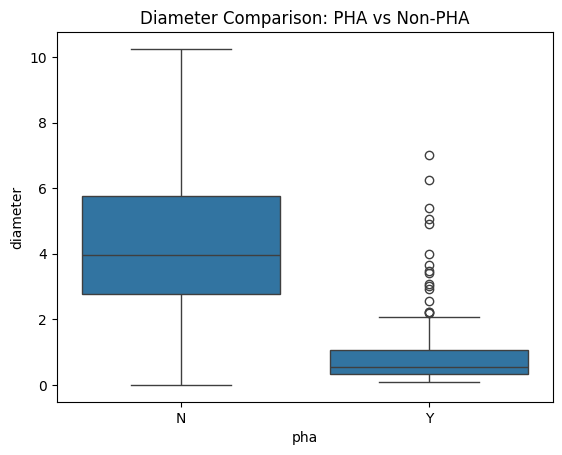

In [ ]:
#asteroid feature class
sns.boxplot(
    data=df,
    x="pha",
    y="diameter"
)

plt.title("Diameter Comparison: PHA vs Non-PHA")

plt.show()

In [ ]:
#Random Forest
# Check class imbalance

print("Class counts:")
print(df["pha"].value_counts())

print("\nClass percentages:")
print(df["pha"].value_counts(normalize=True) * 100)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape)
print("Testing records:", X_test.shape)

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Random Forest training completed!")


Class counts:
pha
N    936537
Y      2066
Name: count, dtype: int64

Class percentages:
pha
N    99.779886
Y     0.220114
Name: proportion, dtype: float64


ValueError: Input contains NaN

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
#Split data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape)
print("Testing records:", X_test.shape)

ValueError: Input contains NaN

**Regression**

import libarires

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFromModel

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import ExtraTreesRegressor

import warnings
warnings.filterwarnings("ignore")

Read the CSV file

In [ ]:
df = pd.read_csv("/content/pha_dataset.csv", low_memory=False)

print("Dataset loaded successfully")

In [ ]:
#Examine shape, columns and data types
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

In [ ]:
display(df.describe().T)

In [ ]:
display(df.describe(include="object").T)

In [ ]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing)

In [ ]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Asteroid Dataset")
plt.show()

In [ ]:
print("Rows before removing missing diameter:",
      len(df))

df = df.dropna(subset=["diameter"])

print("Rows after removing missing diameter:",
      len(df))

print("Remaining missing diameter:",
      df["diameter"].isnull().sum())

In [ ]:
df = df[df["diameter"] > 0].copy()

print("Final rows with valid diameter:", len(df))

In [ ]:
print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

In [ ]:
# Identifier columns
identifier_cols = [
    "id",
    "spkid",
    "pdes",
    "full_name",
    "name",
    "orbit_id"
]

# Classification and target-related leakage columns
leakage_cols = [
    "pha",
    "neo",
    "class",
    "moid",
    "moid_ld"
]

# Derived orbital features
derived_cols = [
    "ad",
    "n",
    "per",
    "per_y"
]

# Remove all uncertainty/sigma columns
sigma_cols = [
    col for col in df.columns
    if "sigma" in col.lower()
]

drop_cols = (
    identifier_cols +
    leakage_cols +
    derived_cols +
    sigma_cols
)

df = df.drop(
    columns=drop_cols,
    errors="ignore"
)

print("Shape after dropping unnecessary columns:", df.shape)

In [ ]:
# Constant columns
constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("Constant columns:", constant_cols)

df = df.drop(columns=constant_cols)

In [ ]:
unique_cols = [
    col for col in df.columns
    if col != "diameter"
    and df[col].nunique(dropna=True) == df[col].notna().sum()
    and (
        df[col].dtype == "object"
        or col.lower() in ["epoch", "epoch_mjd", "epoch_cal"]
    )
]

print("Potential identifier-like unique columns:", unique_cols)

df = df.drop(columns=unique_cols, errors="ignore")

In [ ]:
if "e" in df.columns:
    df = df[df["e"].isna() | (df["e"] >= 0)]

if "a" in df.columns:
    df = df[df["a"].isna() | (df["a"] > 0)]

if "albedo" in df.columns:
    df = df[
        df["albedo"].isna() |
        ((df["albedo"] >= 0) & (df["albedo"] <= 1))
    ]

print("Shape after invalid value checks:", df.shape)

In [ ]:
print(df.select_dtypes(include=np.number).describe().T)

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["diameter"],
    bins=50,
    kde=True
)

plt.title("Distribution of Asteroid Diameter")
plt.xlabel("Diameter (km)")
plt.ylabel("Frequency")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["H"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Absolute Magnitude")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["albedo"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of Albedo")
plt.show()

In [ ]:
columns = [
    col for col in
    ["diameter", "H", "albedo", "e", "a", "i"]
    if col in df.columns
]

for col in columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Outlier Analysis - {col}")

    plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="H",
    y="diameter",
    alpha=0.4
)

plt.title("Diameter vs Absolute Magnitude")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="albedo",
    y="diameter",
    alpha=0.4
)

plt.title("Diameter vs Albedo")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="albedo",
    y="diameter",
    alpha=0.4
)

plt.title("Diameter vs Albedo")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="e",
    y="diameter",
    alpha=0.4
)

plt.title("Diameter vs Eccentricity")
plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="a",
    y="diameter",
    alpha=0.4
)

plt.title("Diameter vs Semi-Major Axis")
plt.show()

In [ ]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Asteroid Features")
plt.show()

In [ ]:
pair_cols = [
    col for col in
    ["diameter", "H", "albedo", "e", "a", "i"]
    if col in df.columns
]

sns.pairplot(
    df[pair_cols].dropna().sample(
        min(1000, len(df)),
        random_state=42
    )
)

plt.show()

In [ ]:
angle_cols = ["om", "w", "ma"]

for col in angle_cols:

    if col in df.columns:

        radians = np.deg2rad(df[col])

        df[col + "_sin"] = np.sin(radians)

        df[col + "_cos"] = np.cos(radians)

        df.drop(columns=[col], inplace=True)

print(df.columns.tolist())

In [ ]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

skew_values = df[numeric_cols].skew().sort_values(
    ascending=False
)

display(skew_values)

In [ ]:
for col in ["diameter", "H", "albedo", "e", "a"]:

    if col in df.columns:

        Q1 = df[col].quantile(0.25)

        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR

        upper = Q3 + 1.5 * IQR

        outliers = df[
            (df[col] < lower) |
            (df[col] > upper)
        ]

        print(
            col,
            "Outliers:",
            len(outliers)
        )

In [ ]:
X = df.drop(columns=["diameter"])

y = df["diameter"]

# Keep only numeric predictors for this initial experiment
X = X.select_dtypes(include=np.number)

print("Feature Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nSelected Features:")
print(X.columns.tolist())

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

In [ ]:
y_train_log = np.log1p(y_train)

print("Training target transformed successfully")

In [ ]:
preprocessor = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Data After Preprocessing:",
      X_train_processed.shape)

print("Testing Data After Preprocessing:",
      X_test_processed.shape)

In [ ]:
selector_model = ExtraTreesRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

selector_model.fit(
    X_train_processed,
    y_train_log
)

importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": selector_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")

plt.show()

In [ ]:
feature_selector = SelectFromModel(
    estimator=ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    threshold="median"
)

X_train_selected = feature_selector.fit_transform(
    X_train_processed,
    y_train_log
)

X_test_selected = feature_selector.transform(
    X_test_processed
)

print("Features Before Selection:",
      X_train_processed.shape[1])

print("Features After Selection:",
      X_train_selected.shape[1])

In [ ]:
lr_model = LinearRegression()

lr_model.fit(
    X_train_selected,
    y_train_log
)

lr_predictions_log = lr_model.predict(
    X_test_selected
)

lr_predictions = np.expm1(lr_predictions_log)

lr_predictions = np.maximum(lr_predictions, 0)

In [ ]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_selected,
    y_train_log
)

rf_predictions_log = rf_model.predict(
    X_test_selected
)

rf_predictions = np.expm1(rf_predictions_log)

rf_predictions = np.maximum(rf_predictions, 0)

In [ ]:
gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(
    X_train_selected,
    y_train_log
)

gb_predictions_log = gb_model.predict(
    X_test_selected
)

gb_predictions = np.expm1(gb_predictions_log)

gb_predictions = np.maximum(gb_predictions, 0)

In [ ]:
def evaluate_model(model_name, actual, predicted):

    mae = mean_absolute_error(
        actual,
        predicted
    )

    mse = mean_squared_error(
        actual,
        predicted
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        actual,
        predicted
    )

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [ ]:
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        lr_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
)

results.append(
    evaluate_model(
        "Gradient Boosting",
        y_test,
        gb_predictions
    )
)

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="RMSE",
        ascending=True
    )
)

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Regression Models")

plt.ylabel("RMSE")

plt.show()

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("R2 Score Comparison")

plt.show()

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.5
)

min_value = min(y_test.min(), rf_predictions.min())

max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Diameter (km)")

plt.ylabel("Predicted Diameter (km)")

plt.title("Random Forest: Actual vs Predicted Diameter")

plt.show()

In [ ]:
residuals = y_test - rf_predictions

plt.figure(figsize=(8, 5))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.title("Random Forest Residual Distribution")

plt.xlabel("Prediction Error (km)")

plt.show()

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    rf_predictions,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Diameter")

plt.ylabel("Residuals")

plt.title("Residual Analysis")

plt.show()

In [ ]:
selected_feature_names = (
    preprocessor.get_feature_names_out()[
        feature_selector.get_support()
    ]
)

rf_importance = pd.DataFrame({
    "Feature": selected_feature_names,
    "Importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
)

display(rf_importance)

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=rf_importance,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")

plt.show()